# Ejercicio 2

## 1. Descarga del Conjunto de Datos
Cargamos nuestro conjunto de datos, se comprueban las dimensiones del conjunto de datos y se visualizan las primeras filas para verificar la integridad de la información antes de proceder a la agregación de los datos por club.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid")

# Carga de datos individuales
df = pd.read_csv('fifa_22_official_players_data.csv', low_memory=False)

print("--- 1. INFORMACIÓN A NIVEL DE JUGADOR INDIVIDUAL ---")
print(f"Dimensiones: {df.shape[0]} jugadores, {df.shape[1]} atributos.")
print(df[['overall', 'potential', 'age', 'value_eur']].describe())

--- 1. INFORMACIÓN A NIVEL DE JUGADOR INDIVIDUAL ---
Dimensiones: 19239 jugadores, 73 atributos.
            overall     potential           age     value_eur
count  19239.000000  19239.000000  19239.000000  1.916500e+04
mean      65.772182     71.079370     25.210822  2.850452e+06
std        6.880232      6.086213      4.748235  7.613700e+06
min       47.000000     49.000000     16.000000  9.000000e+03
25%       61.000000     67.000000     21.000000  4.750000e+05
50%       66.000000     71.000000     25.000000  9.750000e+05
75%       70.000000     75.000000     29.000000  2.000000e+06
max       93.000000     95.000000     54.000000  1.940000e+08


Tras ejecutar el código podemos observar un análisis detallado de las principales características cuantitativas a nivel de jugador individual. 


### 1.1 Exploración del Conjunto de Datos

#### 1.1.1. Agregación de Datos a Nivel de Club
Agrupamos por la variable categórica del club. Aplicamos funciones de agregación com media, la mediana para resumir las características físicas de la plantilla.
Para ello agrupamos los jugadores por `club_name` y calculamos las estadísticas generales de cada plantilla. Para cada club obtenmos la valoración media actual, la valoración central de los jugadores, su dispersión, velocidada....


In [3]:
# Agregación por club
club_agg = df.groupby('club_name').agg({
    'overall': ['mean', 'median', 'std'],
    'potential': ['mean', 'max', 'median'],
    'age': ['mean', 'std'],
    'pace': 'mean',
    'shooting': 'mean',
    'passing': 'mean',
    'dribbling': 'mean',
    'defending': 'mean',
    'physic': 'mean',
    'value_eur': 'sum' # Valor económico total de la plantilla
}).reset_index()

# Aplanar los nombres de las columnas multinivel
club_agg.columns = ['_'.join(col).strip('_') if col[1] else col[0] for col in club_agg.columns.values]

print("\n--- 2. INFORMACIÓN AGREGADA A NIVEL DE CLUB ---")
print(club_agg.head())
print(f"Total de clubes analizados: {club_agg.shape[0]}")


--- 2. INFORMACIÓN AGREGADA A NIVEL DE CLUB ---
               club_name  overall_mean  overall_median  overall_std  \
0  1. FC Heidenheim 1846     66.925926            68.0     4.480092   
1   1. FC Kaiserslautern     62.821429            63.5     3.559584   
2             1. FC Köln     69.161290            71.0     6.330333   
3        1. FC Magdeburg     62.107143            62.5     2.739820   
4         1. FC Nürnberg     65.689655            66.0     4.818887   

   potential_mean  potential_max  potential_median   age_mean   age_std  \
0       71.185185             76              71.0  24.666667  4.057282   
1       68.142857             76              67.0  24.285714  3.619465   
2       75.451613             82              76.0  24.225806  4.256052   
3       67.500000             73              68.0  23.750000  3.329164   
4       70.896552             79              71.0  24.689655  4.818887   

   pace_mean  shooting_mean  passing_mean  dribbling_mean  defending_mean

En los primeros resultados obtenidos podemos ver que el primer club tiene una valoración media de 71,19 y un valor aproximado de 42.5 millones de euros.

La desviación estándar permite conocer la homogeniedad de la plantilla, cuanto menor sea, más parecidos los jugadores entre si. Por ejemplo, el equipo 1 tiene un dispersión más reducida que la del equipo 2.

Esta transformación cambia el análisis de nivel individual a nivel de club y nos permite comparar la calidad media, el potencial y las características deportivas de cada club. 


#### 1.1.2 Análisis de Distribuciones
A continuación mediante el uso de histogramas evaluamos la forma de la distribución de los datos aplicada al potencial medio de los clubes para poder dividir los datos en tres clases distintas (Bajo, Medio, Alto)

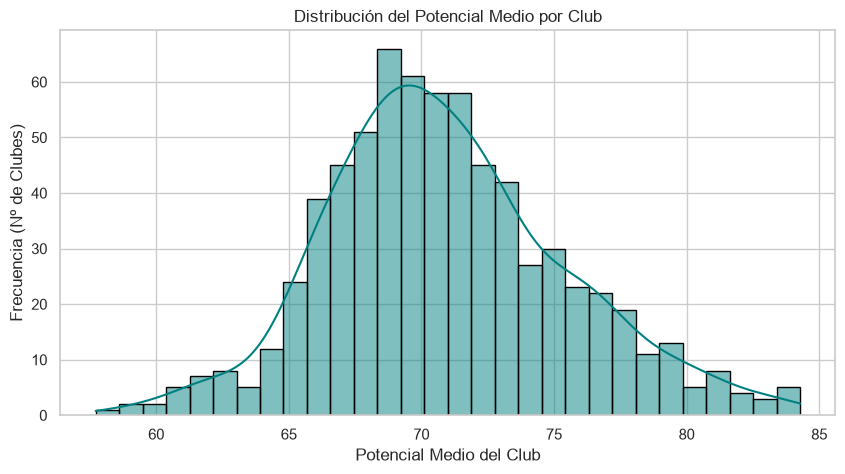

In [4]:
# 3. Distribución del potencial medio de los clubes
plt.figure(figsize=(10, 5))
sns.histplot(club_agg['potential_mean'], kde=True, bins=30, color='teal', edgecolor='black')
plt.title('Distribución del Potencial Medio por Club')
plt.xlabel('Potencial Medio del Club')
plt.ylabel('Frecuencia (Nº de Clubes)')
plt.show()

En cuanto al histograma generado la mayor concentración de clubes se encuentra entre un 65 y 75. Los clubes con un potencial medio más bajo aparecen en la parte izquierda mientras que los clubes con un potencial más alto a la derecha. La mayoría de los equipos presentan un potencial medio, mientras que solo una cantidad reducida alcanzan valores especialmente alto. Indicando que hay menos equipos con un potencial elevado. 

#### 1.1.3 Detección de valores Atipicos 
La detección de valores atípicos nos permite identificar observaciones que se alejan mucho del comportamiento habitual del conjunto de datos. Buscamos valores extremos como jugadores con valores económicos muy superiores al resto, datos poco representativos, valores nulos. La detección de estos valores evita que nuestro modelo se llene de ruido. 

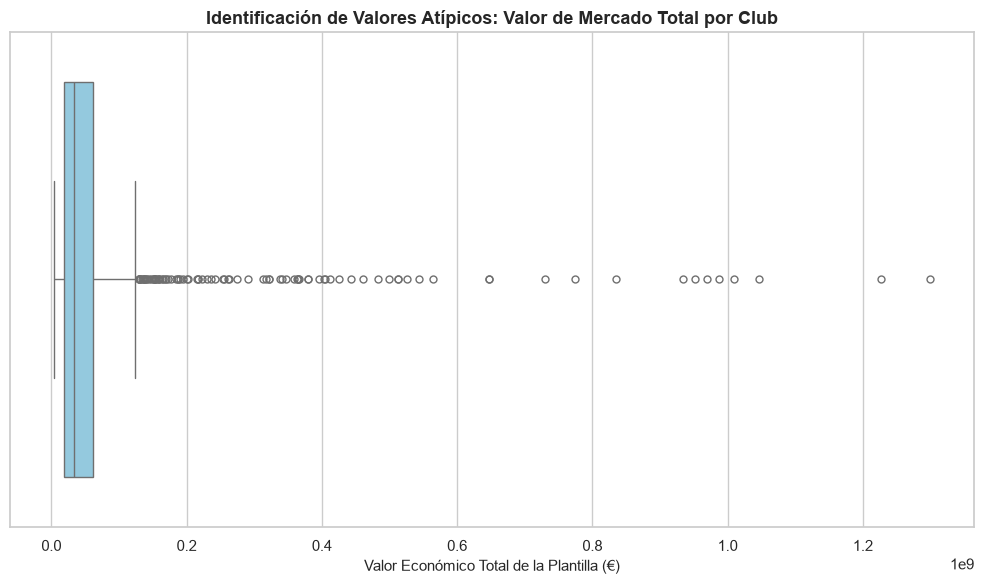

Límite inferior IQR: -46,050,000.00 €
Límite superior IQR: 126,510,000.00 €
Número de clubes identificados como outliers económicos: 90


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
plt.figure(figsize=(10, 6))

# Generación del boxplot para la variable agregada 'value_sum' (Valor total de mercado del club)
sns.boxplot(x=club_agg['value_eur_sum'], color='skyblue', fliersize=5)

plt.title('Identificación de Valores Atípicos: Valor de Mercado Total por Club', fontsize=13, fontweight='bold')
plt.xlabel('Valor Económico Total de la Plantilla (€)', fontsize=11)
plt.tight_layout()

# Guardar la figura para incluirla en el informe PDF final
plt.savefig('boxplot_outliers_clubes.png', dpi=300)
plt.show()

# Cálculo cuantitativo de los límites IQR para respaldar el gráfico
Q1 = club_agg['value_eur_sum'].quantile(0.25)
Q3 = club_agg['value_eur_sum'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_count = ((club_agg['value_eur_sum'] < lower_bound) | (club_agg['value_eur_sum'] > upper_bound)).sum()
print(f"Límite inferior IQR: {lower_bound:,.2f} €")
print(f"Límite superior IQR: {upper_bound:,.2f} €")
print(f"Número de clubes identificados como outliers económicos: {outliers_count}")

El elemento visual nos permite detectar clubes cuyo valor económico total se aleja del comportamiento habitual. El límite inferior es de −46.050.000 € y el superiror 26.510.000 €. Y se han identificado un total de 90 clubes con esos valores.

Como el valor económico de una plantilla no puede ser negativo, el límite inferiro no tiene una interpretación, por lo tanto los clubes con un límite superior se considerar atípicos. Con la ayuda de el diagrama de caja como elemento visual. Podemos ver que la mayoría de clubes se concentra en valores relativamente bajos, miertras que numeros puntos alejados representan los clubes con un valor económico demasiado alto. 



#### 1.1.4. Análisis de Correlaciones
Con la ayuda de un mapa de calor (Heat Map) estudiamos las relaciones entre las variables numéricas de nuestro dataset. 



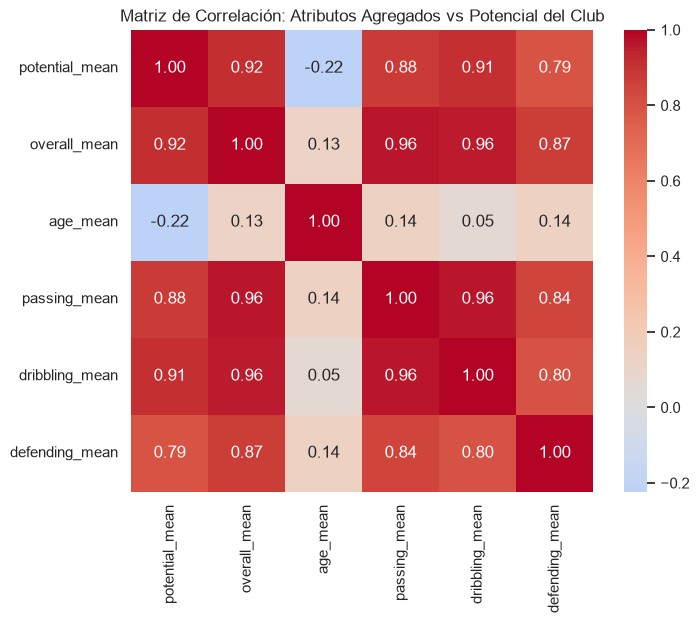

In [6]:
# Selección de variables agregadas numéricas para el análisis de correlación
cols_corr = ['potential_mean', 'overall_mean', 'age_mean', 'passing_mean', 'dribbling_mean', 'defending_mean']
matriz_corr = club_agg[cols_corr].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', center=0, square=True, fmt='.2f')
plt.title('Matriz de Correlación: Atributos Agregados vs Potencial del Club')
plt.show()

La matriz de correlación generada, muestra una relacción muy positiva entre la calidad media de los clubes y sus características deportivas, Concretamente, el `overall_mean` con el `potencial_mean`, indicando que los clubes con una valoración media más alta suelen tener mayor potencial.
Las correlaciones más elevadas son entre `overall_mean` con `passing` y `dribbling` con un valor de 0.96. Esto significa que los clubes mejor valorados suelen tener jugadores con mejores capacidades de pase y regate. 

Finalmente la edad media presenta correlaciones debiles con el resto de variables. Por lo qye la edad no  parece ser un factor determinante para explicar la calidad o pontencial medio del club. 

### 1.2 Preprocesamiento y Transformación de Datos

En este apartado preparamos el dataset para que pueda ser analizado correctamente. Se revisan los tipos de datos se localizan valores nulos, se transforman algunos datos... Además se estudia el contenido y comportamiento del dataser. Analizando su tamaño, las variables disponinles...

#### 1.2.1 Agregar los atributos individuales de los jugadores por club 

Para ello vamos a agrupar el conjunto de datos por el nombre del equipo y aplicar funciones como la media, la mediana y la desviación estandar.

In [7]:
import pandas as pd
import numpy as np

# 1. Agrupar los datos por club y calcular estadísticos agregados
club_agg = df.groupby('club_name').agg({
    # Valoración y Potencial (Media, Máximo y Mediana)
    'overall': ['mean', 'median', 'std'],
    'potential': ['mean', 'max', 'std'],
    
    # Perfil Demográfico (Edad media y desviación para ver si hay mezcla de jóvenes y veteranos)
    'age': ['mean', 'std'],
    
    # Atributos Físicos, Técnicos y Mentales (Medias de la plantilla)
    'pace': 'mean',
    'shooting': 'mean',
    'passing': 'mean',
    'dribbling': 'mean',
    'defending': 'mean',
    'physic': 'mean',
    
    # Aspectos económicos (Suma total del valor de mercado y salarios de la plantilla)
    'value_eur': 'sum',
    'wage_eur': 'sum',
    
    # Recuento de jugadores en la plantilla del club
    'sofifa_id': 'count'
}).reset_index()

# 2. Aplanar el índice multinivel generado en las columnas
club_agg.columns = ['_'.join(col).strip('_') if col[1] else col[0] for col in club_agg.columns.values]

# Renombrar la columna de conteo para mayor claridad
club_agg.rename(columns={'sofifa_id_count': 'quad_size'}, inplace=True)

print(f"Dimensiones del dataset agregado por club: {club_agg.shape[0]} clubes y {club_agg.shape[1]} atributos.")
club_agg.head(3)

Dimensiones del dataset agregado por club: 701 clubes y 18 atributos.


,club_name,overall_mean,overall_median,overall_std,potential_mean,potential_max,potential_std,age_mean,age_std,pace_mean,shooting_mean,passing_mean,dribbling_mean,defending_mean,physic_mean,value_eur_sum,wage_eur_sum,quad_size
0,1. FC Heidenheim 1846,66.925926,68.0,4.480092,71.185185,76,3.351659,24.666667,4.057282,68.041667,53.833333,57.083333,62.583333,53.416667,68.166667,42500000.0,249000.0,27
1,1. FC Kaiserslautern,62.821429,63.5,3.559584,68.142857,76,3.545621,24.285714,3.619465,69.960000,49.520000,53.120000,60.000000,45.720000,64.280000,21280000.0,42800.0,28
2,1. FC Köln,69.161290,71.0,6.330333,75.451613,82,4.015293,24.225806,4.256052,66.703704,54.925926,61.925926,67.370370,56.148148,67.111111,101995000.0,432050.0,31


La desviación estándar permite conocer la variedad interna de cada plantilla. Por ejemplo el equipo 2 presenta un desviación de 6,33 lo que indica mayor diferencia de nivel entre sus jugadores mientras que el equipo 1 tiene una desviación menor de 3,56

La agregación permite comparar los clubes según las variables numéricas. 

#### 1.2.2 Discretización  de Variables

En este apartado trasformaremos la variable numérica `club_potencial`en una variable categórica con tres niveles: **Bajo**, **Medio** y **Alto**. Esta transformación permite plantear un problema de clasificación. 

Para realizar la categorización utilizaremos `pd.qcut()` que divide los datos según sus cuantiles. De esta manera, cada clase contiene aproximadamente el mismo número de clubles, los límites se obtienen a partir de la distribución de los datos. 
Con el parametro `q=3` dividimos la distribución en tres partes iguales. 

In [16]:
# Si la variable aún no existe, se crea a partir del potencial medio del club
club_agg['club_potential'] = club_agg['potential_mean']

# Discretización en tres clases según los terciles de la distribución
club_agg['club_potential_tier'] = pd.qcut(
    club_agg['club_potential'],
    q=3,
    labels=['Bajo', 'Medio', 'Alto']
)

# Comprobar la distribución de las clases
print("Distribución de las categorías:")
print(club_agg['club_potential_tier'].value_counts().sort_index())

# Mostrar los intervalos utilizados como puntos de corte
puntos_corte = club_agg['club_potential'].quantile([0, 1/3, 2/3, 1])
print("\nPuntos de corte utilizados:")
print(puntos_corte)

Distribución de las categorías:
club_potential_tier
Bajo     234
Medio    234
Alto     233
Name: count, dtype: int64

Puntos de corte utilizados:
0.000000    57.714286
0.333333    68.752874
0.666667    72.333333
1.000000    84.281250
Name: club_potential, dtype: float64


Tras ejecutar el código obtenemos la distribución de categorías. En total se han analizado 701 clubes, las clases están practicamente equilibradas gracias a la función `pd.qcut`que divide los datos en tres grupos con aproximadamente el mismo número de observaciones. Para los puntos de corte se han calculado mediante terciles. El objetivo no es crear rangos numéricos iguales, sino dividir los clubes dentro de su posición relativa dentro de la distribución. 

#### 1.2.3. Codificación de Variables
En cuanto a la codificación de variables categóricas, la columnas de texto como `club_name` al ser identificadores y no representan características útiles para predecir el potencial las excluimos. En cuanto a la variable `club_potencial_tier` se codifica como variable objetivo para facilitar el entrenamiento y la evaluación del modelo.

In [17]:
from sklearn.preprocessing import LabelEncoder

# Codificar la variable objetivo
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(
    club_agg['club_potential_tier']
)

print("Correspondencia entre categorías y números:")
for categoria, codigo in zip(
    label_encoder.classes_,
    range(len(label_encoder.classes_))
):
    print(f"{categoria} -> {codigo}")

Correspondencia entre categorías y números:
Alto -> 0
Bajo -> 1
Medio -> 2


Finalmente tras codificar la variable objetivo, el Alto se representa con un 0, Bajo con un 1 y Medio con un 2. Para ello se ha utilizado `LabelEncoder`

#### 1.2.4. Escalado y Normalización


En cuanto al escalado, utilizaremos el escalado Robusto. Esta técnica centra cada variable tomando como referencia la mediana y la escala mediante el rango, siendo más sensible a los valores atípicos que el escalado estandar. Para evitar que distorsionen la normalización del resto de los datos. 

Se ha seleccionado este escalado, porque la variable `value_eur_sum`presenta valores económicos muy elevados y una distribución con posibles exptremos. Con el uso de este escalado las variables deportivas y económicas quedan en escalas comparables sin que los clubles con valores de mercado más elevados dominen el análisis. 

Para aplicar este escalado en el código incluimos elementos como `fit_transform()` que calcula la mediana y el rango utilizando `X_train`y después se transforman esos datos. Luego con `transform()` aplicamos los mismos valores a `X_test`. 

La fórmula que se aplica es: 


 $$ x' = \frac{x-\text{mediana}}{Q3-Q1} $$

Siendo `Q1` primer cuartil y  `Q3` el tercer cuartil.


In [ ]:
from sklearn.preprocessing import RobustScaler
# Creamos el objeto RobustScaler
scaler = RobustScaler()
# Calculamos la mediana y el rango de cada variable
X_scaled = pd.DataFrame(
    scaler.fit_transform(X), # Transformamos todas las variables de X
    columns=X.columns,
    index=X.index     # Mantenemos los nombres de las columnas y los ínidices originales 
)

print(X_scaled.head())

   overall_mean  overall_median  overall_std  potential_mean  potential_max  \
0      0.296836        0.333333    -0.177615        0.145763           -0.5   
1     -0.426423       -0.416667    -0.645641       -0.413929           -0.5   
2      0.690733        0.833333     0.763126        0.930652            0.5   
3     -0.552288       -0.583333    -1.062443       -0.532194           -1.0   
4      0.078991        0.000000    -0.005357        0.092664            0.0   

   potential_std  age_mean   age_std  pace_mean  shooting_mean  passing_mean  \
0      -0.550312 -0.263158 -0.508508  -0.053422       0.337326      0.069626   
1      -0.361972 -0.458996 -0.984016   0.498719      -0.351160     -0.572888   
2       0.094086 -0.489794 -0.292626  -0.438518       0.511724      0.854681   
3      -1.064742 -0.734394 -1.299309   0.452667      -0.427776     -0.397804   
4      -0.095081 -0.251340  0.318663  -0.120765       0.142920     -0.081057   

   dribbling_mean  defending_mean  physic_me

Tras aplicar el escalado Robusto podemos observar que todas las variables quedan en una escala comparable. Los valores más cercanos representan clubes con características próximas a la mediana, mientras que los valores positivos indican valores superiores y con los negativos valores inferiores. 

Este escalado facilita la comparación entre variables deportivas, económicas y demográficas evitando que las cantidades económicas dominen debidos a sus valores más elevados. 

### 1.3. Preguntas y Respuestas


### 1.3.1. ¿Cuál es la distribución de los clubes de fútbol en base a la categoría de potencial del club definida?

La distribución de los clubes según la categoría es bastante equilibrada: 

* **Bajo**: 234 clubes, 33,4%
* **Medio**: 234 clubes, 33,4%
* **Alto**: 233 clubes, 33,2%
En total se han analizado 701 clubes. Esta distribución se debe a el uso de terciles mediante `pd.qcut()`dividiendo a los clubes en tres grupos con cantidades similares. 

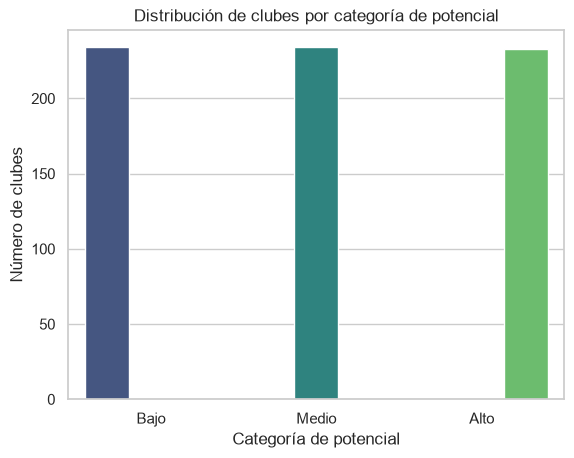

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

orden = ['Bajo', 'Medio', 'Alto']

sns.countplot(
    data=club_agg,
    x='club_potential_tier',
    order=orden,
    hue='club_potential_tier',
    palette='viridis',
    legend=False
)

plt.title('Distribución de clubes por categoría de potencial')
plt.xlabel('Categoría de potencial')
plt.ylabel('Número de clubes')
plt.show()

El gráfico de barras muestra que las tres categorías son practicamente iguales, confirmando que no existe un desiquilibrio significativo entre las categorías. 

#### 1.3.2 ¿Existen diferencias agregadas medibles (p. ej., edad media del equipo, visión, compostura técnica) entre los clubes de alto potencial y los clubes estándar?

Sí, exites diferencias agregadas medibles entre los clubes de potencial alto y estándar. Para comprobarlo, calculamos la media de varias características y lo representamos de manera visual con un gráfico de radar. 

In [27]:
import plotly.graph_objects as go

variables = [
    'age_mean',
    'overall_mean',
    'passing_mean',
    'dribbling_mean',
    'defending_mean',
    'physic_mean'
]

nombres = [
    'Edad media',
    'Valoración general',
    'Pase',
    'Regate',
    'Defensa',
    'Físico'
]

comparacion = club_agg.groupby('club_potential_tier')[variables].mean()

# Normalización para comparar las variables en la misma escala
comparacion_norm = (
    comparacion - comparacion.min()
) / (
    comparacion.max() - comparacion.min()
)

fig = go.Figure()

for categoria, color in [('Medio', 'royalblue'), ('Alto', 'crimson')]:
    valores = comparacion_norm.loc[categoria].tolist()
    valores.append(valores[0])

    fig.add_trace(go.Scatterpolar(
        r=valores,
        theta=nombres + [nombres[0]],
        fill='toself',
        name=categoria,
        line=dict(color=color)
    ))

fig.update_layout(
    title='Comparación interactiva entre clubes de potencial medio y alto',
    polar=dict(radialaxis=dict(visible=True, range=[0, 1])),
    showlegend=True
)

fig.show()

Como podemos observar en este gráfico radar, la zona de los clubes altos se extiene más con variables como la valoración general, el regate, la defensa y el físico. Indicando que demuestra mejores características que el club de rango medio. 

Ademñas se observa que los clubes alto tienen una media potencial y general superiores, lo cual confirma que la clasificación es coherente con los datos. El tema de la edad media debe interpretarse como una edad inferior podría indicar una plantilla más jóven con poca experiencia y una edad superior con una plantilla con experiencia. 

En conclusión el gráfico demuestra que sí existen diferencias agregadas medibles entre ambos clubes.

#### 1.3.3. ¿Cómo varía el perfil de edad y la profundidad técnica del club entre clubes con diferentes niveles (tiers) de potencial?

El perfil de edad y la profundidad técnica puede variar entre los distintos niveles de potencial. Para medir la profundidad técnica agruparemos las pruncipales habilidades deportivas y compararemos sus medias entre las tres categorías.

                      age_mean  profundidad_tecnica
club_potential_tier                                
Bajo                 25.585112            56.280788
Medio                25.204826            58.990199
Alto                 24.843741            62.879871


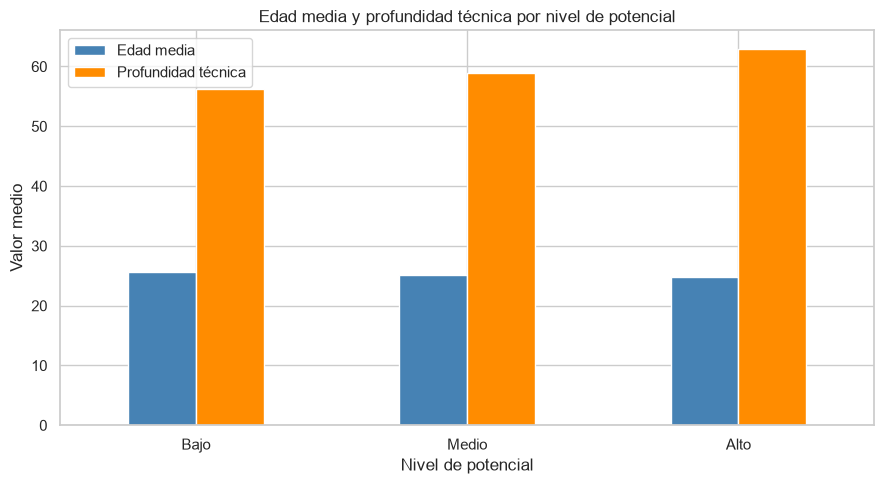

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

atributos_tecnicos = [
    'pace_mean',
    'shooting_mean',
    'passing_mean',
    'dribbling_mean',
    'defending_mean',
    'physic_mean'
]

club_agg['profundidad_tecnica'] = club_agg[atributos_tecnicos].mean(axis=1)

perfil_tiers = club_agg.groupby('club_potential_tier')[
    ['age_mean', 'profundidad_tecnica']
].mean().reindex(['Bajo', 'Medio', 'Alto'])

print(perfil_tiers)

perfil_tiers.plot(
    kind='bar',
    figsize=(9, 5),
    color=['steelblue', 'darkorange']
)

plt.title('Edad media y profundidad técnica por nivel de potencial')
plt.xlabel('Nivel de potencial')
plt.ylabel('Valor medio')
plt.xticks(rotation=0)
plt.legend(['Edad media', 'Profundidad técnica'])
plt.tight_layout()
plt.show()

Los resultados muestran que la profundidad técnica aumenta claramente con el nivel de potencial. Esto indica que los clubes de alto pontencial tien en promedio, plantillas técnicamente más completas. En cambio la edad disminuye ligeramente. Siendo alto 24 años y medio y bajo entre los 25-26 años. Por tanto, los clubes con mayor potencial presentan jugadores mñas jovenes con una profundidad técnica. 
La edad tampoco diferencia tanto mientras que el potencial del club, parece estar relacionado con la calidad y variedad de sus calidades deportivas. 

## 2. Implementación 

En este apartado se contruyen y se entrenan distintops modelos de clasificación con el objetivo de predecir la categoría asignada a cada jugador. Para evaluar la capacidad de generalizaciín el conjunto de datos se divide como dice el enunciado. 

### 2.1. División del Conjunto de Datos.
Dividir el conjunto de datos en entrenamiento y prueba es fundamental para evaluar la cvapacidad de generalización de nuestro modelo frente a dos que nunca ha visto, previniendo el sobreajuste. El conjunto de entrenamiento proporciona un volumen robusto de ejemplos para que el modelo aprenda pratones, mientras que el conjunto de prueba actúa como entorno de validación que simula el mundo real. 

El uso del muestreo estratificado es fundamental para evitar sesgos, especialmente cuando se trabaja con clases desequilibradas. La estratificación obliga al algoritmo a mantener la misma proporción original de las clases tanto en el conjunto de entrenamiento como en el de pruebam garantizando al modelo a aprender y ser evaluado de forma justa en todos los posibles casos. 



Para implementar esta división utlizamos la biblioteca `scikit-learn` utilizando los siguientes elementos:
* `train_test_split`: Se encarga de particionar arreglos o dataframes,
* `test_size=0.20`: Define el tamaño del conjunto de prueba. Dejando automáticamente el 80% al entrenamiento.
* `stratify=y`: ejecuta el muestro estratificado.
* `random_state`: Un valor numéricoque fija la semilla del generador interno. 

In [30]:
from sklearn.model_selection import train_test_split

# Variables predictoras y variable objetivo
X = club_agg.drop(columns=[
    'club_name',
    'club_potential',
    'club_potential_tier'
])

y = club_agg['club_potential_tier']

# División estratificada: 80 % entrenamiento y 20 % prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Tamaño del conjunto de entrenamiento:", X_train.shape)
print("Tamaño del conjunto de prueba:", X_test.shape)

print("\nDistribución en entrenamiento:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nDistribución en prueba:")
print(y_test.value_counts(normalize=True).sort_index())

Tamaño del conjunto de entrenamiento: (560, 18)
Tamaño del conjunto de prueba: (141, 18)

Distribución en entrenamiento:
club_potential_tier
Bajo     0.333929
Medio    0.333929
Alto     0.332143
Name: proportion, dtype: float64

Distribución en prueba:
club_potential_tier
Bajo     0.333333
Medio    0.333333
Alto     0.333333
Name: proportion, dtype: float64


El conjunto de datos se ha dividio en 560 clubes de entrenamiento (80%) y 141 en prueba (15%) teniendo ambos conjuntos 18 variables predictoras.

La distribución de categorías se ha mantenido prácticamente igual en los dos conjuntos. Confirmando que el muestreo estratificado ha funcionado correctamente. Cada grupo conserva una proporción equilibrada de los diferentes ptenciales evitantando que el modelo tenga más ejemplos de una categoría que de otra. 

### 2.2. Entrenamiento 

Para comparar las técnicas de clasificación probaremos varias configuraciones razonables: 

* **Árbol de Decisión**: Se aplico `max_deph` que se encarga de limitar la profundidad máxima del árbol, donde los valores más bajos reducen el sobre ajuste. También se aplico `min_samples_split` para indicar el número de muestras necesarias para dividir el nodo. 
* **Naive Bayes**: Se aplicó `var_smoothing`, añade una pequeña estabilidad a las varianzas, para evitar problemas con variables que tienen una dispersión muy pequeña. 
* **SVM**: Se aplicó `C` que controla el equilibrio entre ajustar bien los datos y mantener un modelo más general. `Kernel` para definir la función utilizada para separar las clases y `gamma` que controla la influencia de cada observación.
* **Random Forest**: Se aplicó `n_estimators` que define el número de árboles que contien el bosque y las mismas configuraciones que se aplicaron en los árboles de decisión. 

También utlizamos la validación cruzada estratificada que se encarga de divisir los datos de entrenamiento en varios subconjuntos, llamados fold. La estratificación garantiza que cada folf mantenga aproximadamente la misma proporción de clubes de las tres categorías. Esto es importante para que ninguna categorñia se infravalore. 

Finalmente seleccionamos la confugaricón con mayor accuracy medio. 


In [32]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

modelos = {
    'Árbol de decisión': (
        DecisionTreeClassifier(random_state=42),
        {
            'max_depth': [3, 5, 8, None],
            'min_samples_split': [2, 5, 10]
        }
    ),
    'Naive Bayes': (
        GaussianNB(),
        {
            'var_smoothing': [1e-9, 1e-8, 1e-7]
        }
    ),
    'SVM': (
        SVC(),
        {
            'C': [0.1, 1, 10],
            'kernel': ['linear', 'rbf'],
            'gamma': ['scale', 'auto']
        }
    ),
    'Random Forest': (
        RandomForestClassifier(random_state=42),
        {
            'n_estimators': [100, 200],
            'max_depth': [None, 5, 10],
            'min_samples_split': [2, 5]
        }
    )
}

resultados = {}

for nombre, (modelo, parametros) in modelos.items():
    busqueda = GridSearchCV(
        estimator=modelo,
        param_grid=parametros,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )

    busqueda.fit(X_train_scaled, y_train)
    resultados[nombre] = busqueda

    print(f'\n{nombre}')
    print('Mejores hiperparámetros:', busqueda.best_params_)
    print(f'Accuracy media: {busqueda.best_score_:.4f}')


Árbol de decisión
Mejores hiperparámetros: {'max_depth': 3, 'min_samples_split': 2}
Accuracy media: 0.9946

Naive Bayes
Mejores hiperparámetros: {'var_smoothing': 1e-09}
Accuracy media: 0.8304

SVM
Mejores hiperparámetros: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Accuracy media: 0.9679

Random Forest
Mejores hiperparámetros: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
Accuracy media: 0.9964


In [33]:
from sklearn.metrics import accuracy_score, classification_report

for nombre, busqueda in resultados.items():
    predicciones = busqueda.best_estimator_.predict(X_test_scaled)

    print(f'\n--- {nombre} ---')
    print(f'Accuracy en prueba: {accuracy_score(y_test, predicciones):.4f}')
    print(classification_report(y_test, predicciones))


--- Árbol de decisión ---
Accuracy en prueba: 0.9929
              precision    recall  f1-score   support

        Alto       1.00      1.00      1.00        47
        Bajo       0.98      1.00      0.99        47
       Medio       1.00      0.98      0.99        47

    accuracy                           0.99       141
   macro avg       0.99      0.99      0.99       141
weighted avg       0.99      0.99      0.99       141


--- Naive Bayes ---
Accuracy en prueba: 0.8156
              precision    recall  f1-score   support

        Alto       0.92      0.74      0.82        47
        Bajo       0.83      0.96      0.89        47
       Medio       0.71      0.74      0.73        47

    accuracy                           0.82       141
   macro avg       0.82      0.82      0.81       141
weighted avg       0.82      0.82      0.81       141


--- SVM ---
Accuracy en prueba: 0.9574
              precision    recall  f1-score   support

        Alto       1.00      0.98      0.

El mejor modelo es Random Forest ya que obtuvo mayor accuracy media en validación crucada concretamente la mejor configuración fue:



In [34]:
{
    'max_depth': None,
    'min_samples_split': 2,
    'n_estimators': 100
}

{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}

Esto significa que se utilizaron 100 árboles sin limitar su profundidad máxima permitiendo divisir los nodos cuando contienen al menos dos observaciones. Además el modelo obtuvo un accuracy de 99% con valores de precisión, recall y F1 cencanos al 0,99 para las res categorías. Esto demuestra que no solo obtuvo mejores valores durante la validación cruzada, sino que también clasifica correctamente los clubes. 



## 3. Evaluación 



### 3.1. Matriz de Confusión del Mejor Modelo


Para la matriz de confusión de cada algoritmo, utilizaremos el conjunto de prueba ya que contiene los datos que el modelo no ha visto durante el entrenamiento.


Matriz de confusión: Árbol de decisión
[[47  0  0]
 [ 0 47  0]
 [ 0  1 46]]


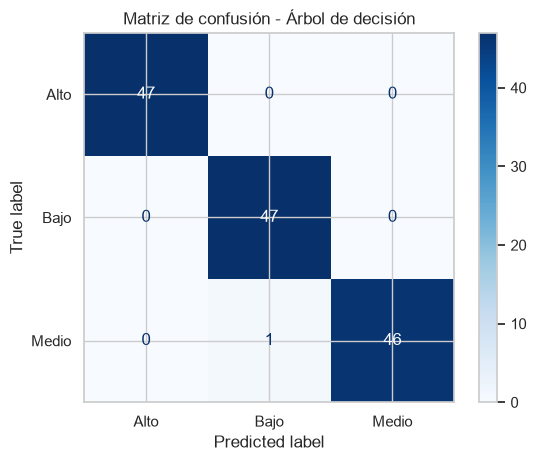


Matriz de confusión: Naive Bayes
[[35  0 12]
 [ 0 45  2]
 [ 3  9 35]]


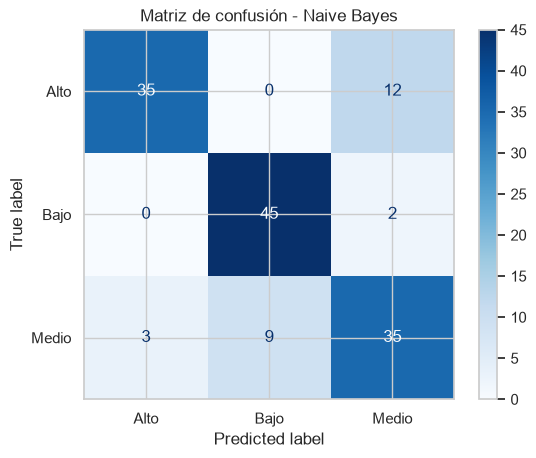


Matriz de confusión: SVM
[[46  0  1]
 [ 0 46  1]
 [ 0  4 43]]


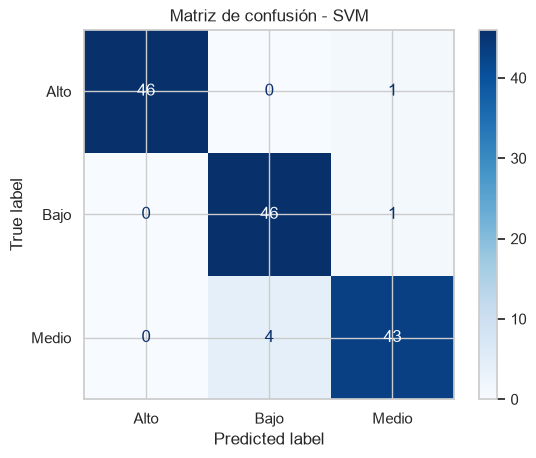


Matriz de confusión: Random Forest
[[47  0  0]
 [ 0 47  0]
 [ 0  2 45]]


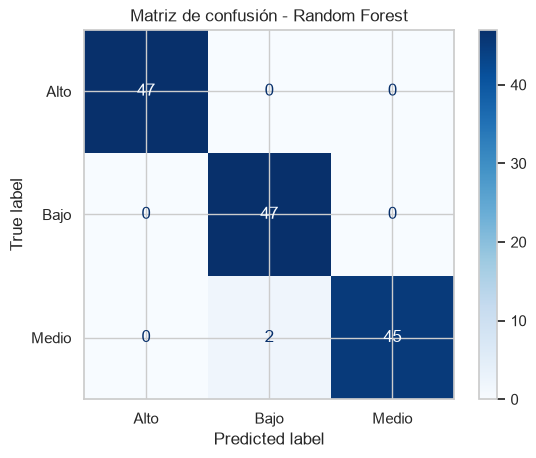

In [35]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for nombre, busqueda in resultados.items():
    modelo = busqueda.best_estimator_
    predicciones = modelo.predict(X_test_scaled)

    matriz = confusion_matrix(
        y_test,
        predicciones,
        labels=['Alto', 'Bajo', 'Medio']
    )

    print(f'\nMatriz de confusión: {nombre}')
    print(matriz)

    visualizacion = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=['Alto', 'Bajo', 'Medio']
    )

    visualizacion.plot(cmap='Blues', values_format='d')
    plt.title(f'Matriz de confusión - {nombre}')
    plt.show()

En cuanto a los resultados obtenidos, la matriz de confusión que presenta los mejores resultados es la del árbol de decisión.
El modelo clasifica 140 de los 141 clubes. Solo comete un error al identificar un club con un potencial medio como bajo. 
Esta matriz presenta una diagonal perfecta con muy pocos errores fuera de ella. Aunque Random Forest obtuvo un mejor accuracy la matriz del árbol está respaldada por sus resultados en el conjunto de prueba. Dicho esto seleccionamos la matriz del Árbol de Decisión, ya que combina un número elevado de aciertos con una estructura más sencilla y interpretable. 

### 3.2. ¿Qué modelo tiene el mejor rendimiento según las métricas de calidad? ¿Por qué?

El mejor modelo con mejor rendimiento es Random Forest. Principalmente porque tiene el mejor accuracy en validación cruzada. Este modelo utiliza la configuración:


In [36]:
{
    'max_depth': None,
    'min_samples_split': 2,
    'n_estimators': 100
}

{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}


Además el conjunto de prueba obtuvo aproximadamente un 99% de accuracy con las métricas de precisión, recall y F1 muy elevadas. Esto indica que clasifica correctamente las tres categorías y generaliza bien ante datos no utilizados durante el entrenamiento. El árbol de decisión también obtuvo unos resultados similares (0,9929 de accuracy y clasificó correctamente 140/141 clubes), pero Random forest alnaza un accuracy medio superior en validazión cruzada (0,9964) y es más robusto al combinar 100 árboles independientes. 

### 3.3. Evalúa los atributos utilizados para entrenar tu Mejor Modelo:

#### 3.3.1. ¿Qué tan bien separados están los tres niveles de potencial de los clubes en el espacio de características (feature space), y sufre la clase intermedia un solapamiento de clasificación significativo con los niveles alto o bajo? ¿Por qué?

Para estudiar cómo se separan las tres categorías en el espacio de características relizaremos dos comprobaciones: 

* Aplicar PCA que es una técnica de reducción de dimensionalidad para reducir las variables a dos dimensiones y representar visualmente los clubes
* Analizaremos la mejor matriz de confusión del mejor modelo para identificar que características se confunden realmente. 

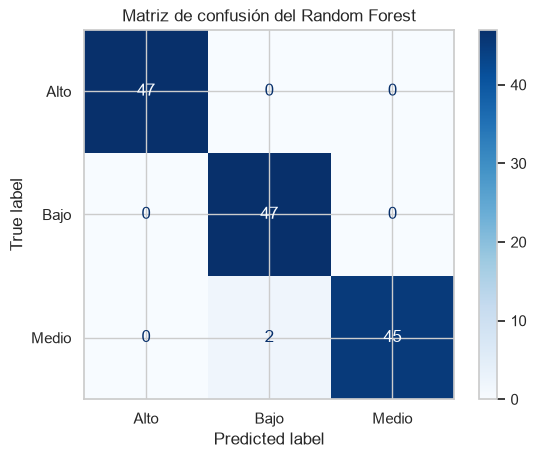

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

mejor_modelo = resultados['Random Forest'].best_estimator_
predicciones = mejor_modelo.predict(X_test_scaled)

matriz = confusion_matrix(
    y_test,
    predicciones,
    labels=['Alto', 'Bajo', 'Medio']
)

visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=['Alto', 'Bajo', 'Medio']
)

visualizacion.plot(cmap='Blues', values_format='d')
plt.title('Matriz de confusión del Random Forest')
plt.show()

Los resultados de la matriz de confusión del Árbol de Decisión muestra una clasificación correcta de 140/141. Donde la única confusión que se produce es entre las categorías bajo y medio, ya que un club de potencial medio se clasifica como uno de bajo. No se observa ninguna confusión entre Medio y Bajo. 

Ahora aplicaremos PCA para resumir las 18 caraterísticas de cada club en solo dos varibales para poder representarlas en un gráfico. El código calcula las dos combinaciones de carácteristicas más importantes y coloca cada club como un punto. Los colores indican si el club pertenece al nivel bajo, medio o alto. 

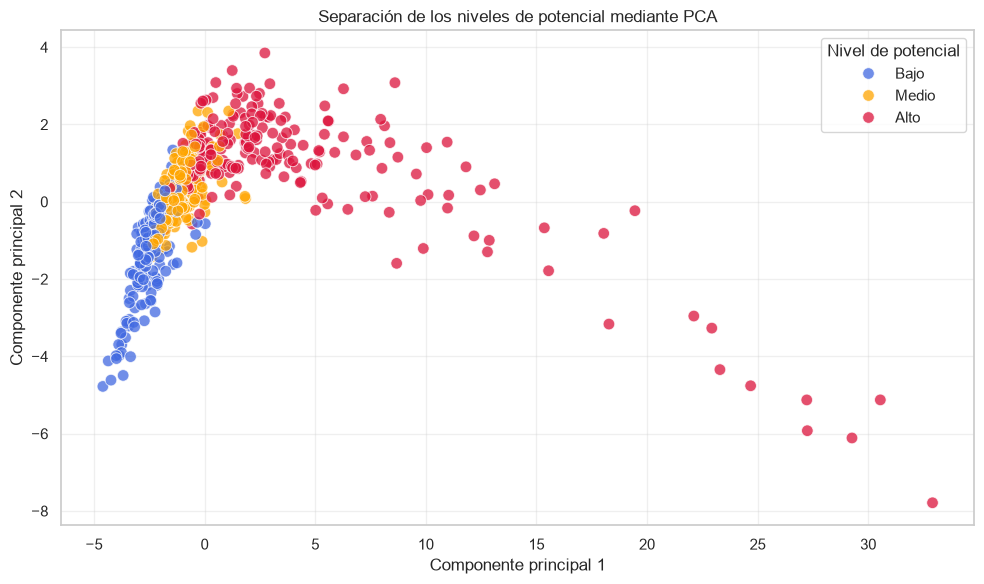

In [38]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Reducir las características escaladas a dos componentes principales
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

grafico_pca = pd.DataFrame({
    'Componente 1': X_pca[:, 0],
    'Componente 2': X_pca[:, 1],
    'Categoría': y.values
})

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=grafico_pca,
    x='Componente 1',
    y='Componente 2',
    hue='Categoría',
    hue_order=['Bajo', 'Medio', 'Alto'],
    palette={
        'Bajo': 'royalblue',
        'Medio': 'orange',
        'Alto': 'crimson'
    },
    s=70,
    alpha=0.75
)

plt.title('Separación de los niveles de potencial mediante PCA')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.legend(title='Nivel de potencial')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

El gráfico muestra que los clubes de potencial bajo aparecen en la zona izquierda, los de potencial alto a la derecha indicando que las características de ambos grupos son bastante diferentes.
Los clubes de potencial medio se situan etre los dos potenciales presentando un solapamiento tanto con los clubes de potencial bajo como con los clubes de potencial medio. 
En general exite una separación clara entre las dos categorías extremas, aunque no perfecta. La clase media presenta mayor mezcla por lo que resulta más dificil de distinguir. 

Por tanto, el PCA confirma que las características utilizadas permiten diferenciar los niveles de potencial entre las dos categorías extremas aunque la media presente un ligero solapamiento. 

#### 3.3.2. Basándose en el rendimiento del modelo, ¿hay evidencia de que la actual discretización en tres clases refleja límites naturales en los datos, o una estrategia de umbrales/distribución de clases alternativa produciría una mejor separación de clases?

La discretización actual mediante terciles produce tres clases muy equilibradas: 234 clubes en Bajo, 234 en Medio y 233 en Alto. Además los modelos obtubieron resultados muy elevados.
Sin embargo, estos resultados no demuestran por si solos que los límites sean naturales. La variable `club_potencial` se ha creado directamente a partir de `potencial_mean` y esta variable parece mantenerse entre las características predictoras. Por lo tanto, puede estar utlizando la misma información con la que se contruyeron las clases y probocae una fuga de información para explicar una separación perfecta.

PAra justificar visualmente los límites utilizados, podemos representar la distribución de potencial medio y marcar los terciles. 

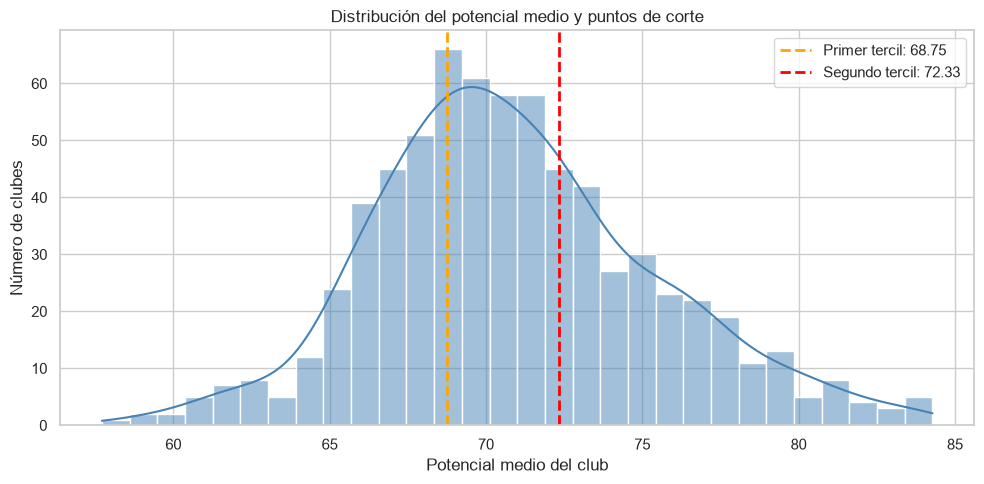

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

cortes = club_agg['club_potential'].quantile([1/3, 2/3])

plt.figure(figsize=(10, 5))

sns.histplot(
    club_agg['club_potential'],
    bins=30,
    kde=True,
    color='steelblue'
)

plt.axvline(
    cortes.iloc[0],
    color='orange',
    linestyle='--',
    linewidth=2,
    label=f'Primer tercil: {cortes.iloc[0]:.2f}'
)

plt.axvline(
    cortes.iloc[1],
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Segundo tercil: {cortes.iloc[1]:.2f}'
)

plt.title('Distribución del potencial medio y puntos de corte')
plt.xlabel('Potencial medio del club')
plt.ylabel('Número de clubes')
plt.legend()
plt.tight_layout()
plt.show()

El gráfico muestra que los clubes se concentran en una misma zona y no aparecen grupos claramente separados. Por eso, los límites 68,75 y 72,33 no parecen naturales, sino puntos elegidos para dividir los clubes en tres grupos de mismo tamaño. La división es equilibrada (234 clubes bajo y medio y 233 clubes alto). Aunque los modelos obtienen un accuracy muy alto, esto se debe a que las categorías se han creado usando el potencial medio que también puede estar entre las variables del modelo.

Dicho esto, la clasificación actual es útil y equilibrada, pero no podemos afirmar que presente grupos naturales. Para esto sería necesario repetir el análisis sin utilizar `potencial_mean` como predictor. 

#### 3.3.3. ¿Qué variables agregadas de la plantilla contribuyen más fuertemente a distinguir entre los tres niveles de potencial, y qué características específicas separan el nivel intermedio de los extremos?

Utilizaremnos el mejor modelo, Random Forest, para medir la importancia de cada variable. Después compararemos las medias de las variables entre las tres categorías mediante una matriz de calor. De esta forma, podremos identificar que características utiliza más el modelo y como evolucionan las categorías. Además para evitar conclusiones engañosas no incluiremos `potencial_mean`, ya que se utilizó para crear las categorías de potencial. 



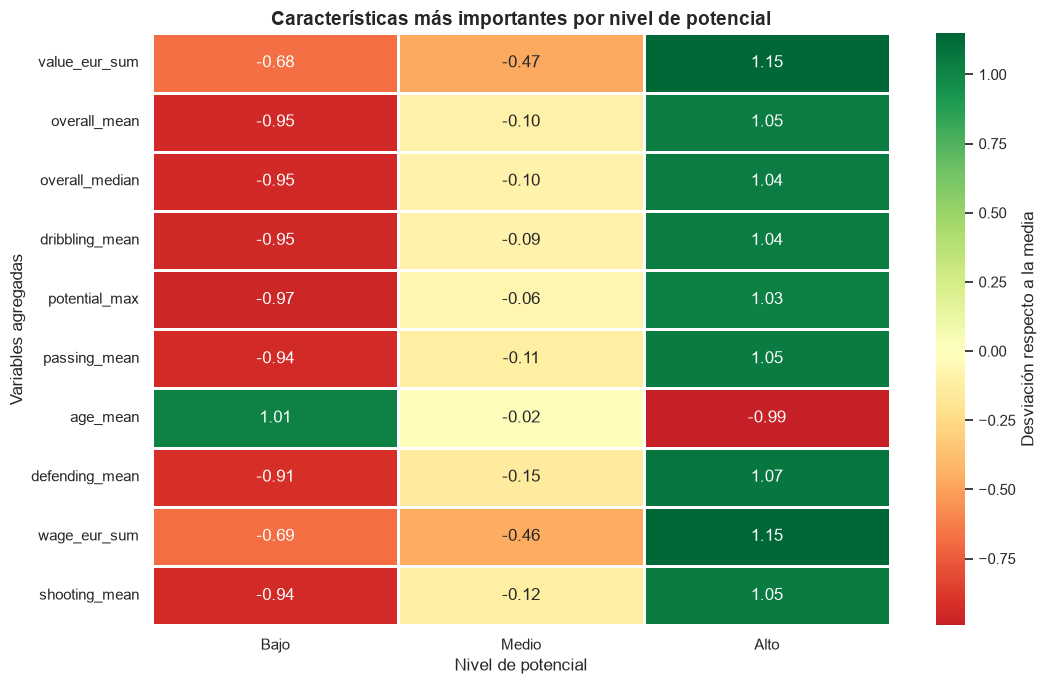

In [48]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Variables agregadas disponibles y válidas para el análisis
variables = [
    'overall_mean',
    'overall_median',
    'overall_std',
    'potential_max',
    'potential_std',
    'age_mean',
    'age_std',
    'pace_mean',
    'shooting_mean',
    'passing_mean',
    'dribbling_mean',
    'defending_mean',
    'physic_mean',
    'value_eur_sum',
    'wage_eur_sum',
    'quad_size'
]

# Calcular las medias por categoría
medias_tier = (
    club_agg
    .groupby('club_potential_tier')[variables]
    .mean()
    .reindex(['Bajo', 'Medio', 'Alto'])
)

# Obtener el mejor modelo Random Forest
mejor_rf = resultados['Random Forest'].best_estimator_

# Obtener las importancias y nombres exactos usados por el modelo
importancias = pd.Series(
    mejor_rf.feature_importances_,
    index=mejor_rf.feature_names_in_
).sort_values(ascending=False)

# Excluir potential_mean para evitar fuga de información
importancias = importancias.drop(
    labels=['potential_mean'],
    errors='ignore'
)

# Mantener únicamente variables presentes en la tabla de medias
top_variables = [
    variable for variable in importancias.head(10).index
    if variable in medias_tier.columns
]

# Normalizar las medias de cada variable
medias_normalizadas = (
    medias_tier[top_variables]
    .sub(medias_tier[top_variables].mean())
    .div(medias_tier[top_variables].std())
)

# Crear la matriz de calor
plt.figure(figsize=(11, 7))

sns.heatmap(
    medias_normalizadas.T,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    center=0,
    linewidths=1,
    linecolor='white',
    cbar_kws={'label': 'Desviación respecto a la media'}
)

plt.title(
    'Características más importantes por nivel de potencial',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Nivel de potencial')
plt.ylabel('Variables agregadas')
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

La matriz de calor muestra que las variables que más diferencian los niveles. En los clubes de potencial bajo, estas variables se representan con valores negativos(con un color rojo) en los clubes de potencial bajo, mientras que las de potencial alto se representan con valores positivos (color verde), por ejemplo `overall_mean` pase de -0,95 en bajo a 1,05 en alto. Esto indica que los clubes de mayor potencial tienen mejores caraterísticas deportivas y mayor capacidad económica. 

La categoría medio presenta valores próximos al cero en casi todas las variables. Por eso, se encuentra entre los extremos pero no siempre está claramente separada de ellos. Esto puede explicar el pequeño solapamiento observado en los modelos.

La `age_mean` muestra todo lo contrario en el potencial bajo es positiva y en el potencial alto es negativa. Indicando que los clubes de alto potencial tienen plantillas más jóvenes.

En conclusión la evidencia muestra que el nivel de potencial se distingue principalmente por la calidad técnica y deportiva de la plantilla y por su valor económico. La categoría intermedia representa un perfil medio.